# Concealed Weapon Detection in PMMW Images

## Workflow

Clean and split the data, select a training configuration, compare lightweight models, assess reliability, and evaluate the final model.

## Imports

In [1]:
from itertools import combinations
from pathlib import Path

import filecmp
import gc
import hashlib
import shutil
import time
import xml.etree.ElementTree as ET

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from IPython.utils.io import capture_output
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou, smooth

## 1. Dataset setup

Load the images and parse the Pascal VOC annotations.

In [2]:
SEED = 42
DATASET_ROOT = Path("pmmw-dataset")

IMAGE_DIR = DATASET_ROOT / "images"
ANNOTATION_DIR = DATASET_ROOT / "Annotations"

if not IMAGE_DIR.exists() or not ANNOTATION_DIR.exists():
    raise FileNotFoundError(f"PMMW dataset not found at {DATASET_ROOT.resolve()}")

image_paths = sorted(IMAGE_DIR.glob("*.jpg"))
xml_paths = sorted(ANNOTATION_DIR.glob("*.xml"))
records = []

for xml_path in xml_paths:
    root = ET.parse(xml_path).getroot()
    width = int(root.findtext("size/width"))
    height = int(root.findtext("size/height"))

    for obj in root.findall("object"):
        box = obj.find("bndbox")
        xmin, ymin, xmax, ymax = [
            int(box.findtext(name)) for name in ("xmin", "ymin", "xmax", "ymax")
        ]
        records.append({
            "image_name": f"{xml_path.stem}.jpg",
            "class_name": obj.findtext("name").strip().lower(),
            "width": width, "height": height,
            "xmin": xmin, "ymin": ymin, "xmax": xmax, "ymax": ymax,
        })

annotations = pd.DataFrame(records)
annotations["box_width"] = annotations["xmax"] - annotations["xmin"]
annotations["box_height"] = annotations["ymax"] - annotations["ymin"]
annotations["relative_box_area"] = (
    annotations["box_width"] * annotations["box_height"]
    / (annotations["width"] * annotations["height"])
)
annotations["invalid_box"] = (
    (annotations["xmin"] < 0) | (annotations["ymin"] < 0)
    | (annotations["xmax"] > annotations["width"])
    | (annotations["ymax"] > annotations["height"])
    | (annotations["box_width"] <= 0) | (annotations["box_height"] <= 0)
)

per_image = annotations.groupby("image_name").agg(
    object_count=("class_name", "size"),
    classes=("class_name", lambda values: ", ".join(sorted(set(values)))),
    has_gun=("class_name", lambda values: "gun" in set(values)),
).reset_index()

images = pd.DataFrame({
    "image_name": [path.name for path in image_paths],
    "image_path": image_paths,
}).merge(per_image, on="image_name", how="left")
images["has_annotation"] = images["object_count"].notna()
images["object_count"] = images["object_count"].fillna(0).astype(int)
images["has_gun"] = images["has_gun"].fillna(False).astype(bool)

C:\Users\ADAM-\AppData\Local\Temp\ipykernel_15048\168049619.py:48: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  images["has_gun"] = images["has_gun"].fillna(False).astype(bool)


## 2. Dataset overview

In [3]:
image_names = {path.stem for path in image_paths}
xml_names = {path.stem for path in xml_paths}
missing_xml = sorted(image_names - xml_names)
missing_images = sorted(xml_names - image_names)
annotated_images = images[images["has_annotation"]]

print(f"Image files:             {len(image_paths):,}")
print(f"XML annotation files:    {len(xml_paths):,}")
print(f"Total bounding boxes:    {len(annotations):,}")
print(f"Gun-positive images:     {annotated_images['has_gun'].sum():,}")
print(f"Gun-negative images:     {(~annotated_images['has_gun']).sum():,}")
print(f"Images without XML:      {len(missing_xml):,}")
print(f"XML files without image: {len(missing_images):,}")
print(f"Invalid bounding boxes:  {annotations['invalid_box'].sum():,}")
print(f"Image dimensions:        {sorted(set(zip(annotations.width, annotations.height)))}")

if missing_xml:
    print("\nImages without annotations:", ", ".join(missing_xml))

Image files:             1,624
XML annotation files:    1,618
Total bounding boxes:    2,445
Gun-positive images:     833
Gun-negative images:     785
Images without XML:      6
XML files without image: 0
Invalid bounding boxes:  0
Image dimensions:        [(284, 631), (286, 635)]

Images without annotations: image_0105, image_0417, image_0419, image_0492, image_1060, image_1468


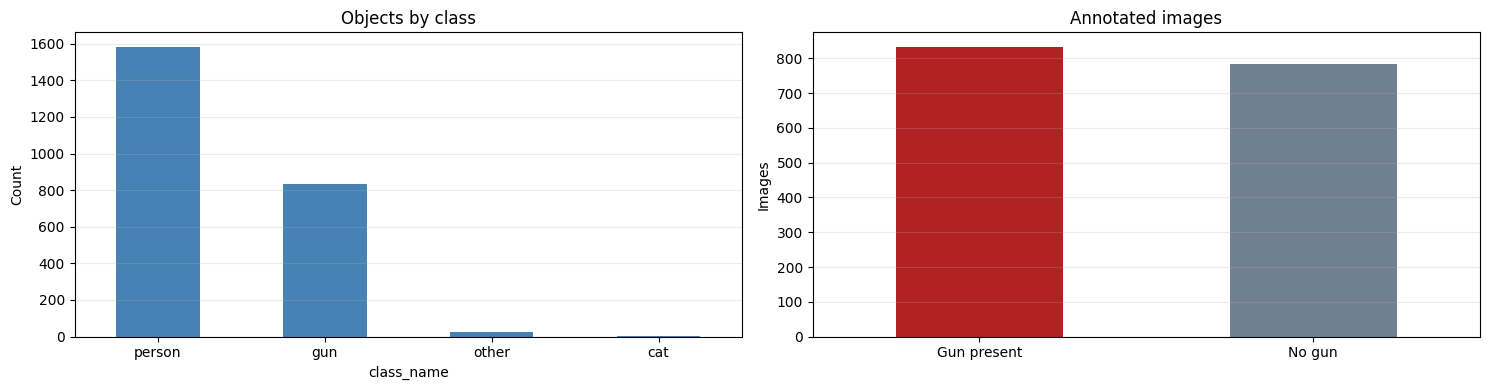

In [4]:
class_counts = annotations["class_name"].value_counts().sort_values(ascending=False)
gun_status = pd.Series({
    "Gun present": int(annotated_images["has_gun"].sum()),
    "No gun": int((~annotated_images["has_gun"]).sum()),
})

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
class_counts.plot.bar(ax=axes[0], color="steelblue", title="Objects by class")
gun_status.plot.bar(ax=axes[1], color=["firebrick", "slategray"], title="Annotated images")
axes[0].set_ylabel("Count")
axes[1].set_ylabel("Images")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Annotation examples

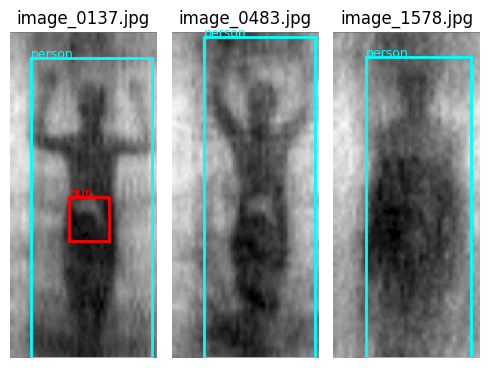

In [5]:
sample_names = annotated_images.sample(3, random_state=SEED)["image_name"]
colours = {"gun": "red", "person": "cyan", "other": "orange", "cat": "yellow"}
fig, axes = plt.subplots(1, 3, figsize=(5, 5))

for ax, image_name in zip(axes.flat, sample_names):
    ax.imshow(Image.open(IMAGE_DIR / image_name), cmap="gray")
    for _, box in annotations[annotations["image_name"] == image_name].iterrows():
        colour = colours.get(box["class_name"], "lime")
        ax.add_patch(Rectangle(
            (box["xmin"], box["ymin"]), box["box_width"], box["box_height"],
            fill=False, edgecolor=colour, linewidth=2,
        ))
        ax.text(box["xmin"], box["ymin"], box["class_name"], color=colour, fontsize=9)
    ax.set_title(image_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Exact duplicates

Identify byte-identical images using SHA-256 hashes and byte comparison.

In [6]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

images["sha256"] = images["image_path"].apply(sha256_file)
duplicate_groups = images.groupby("sha256")["image_path"].apply(list)
duplicate_groups = duplicate_groups[duplicate_groups.apply(len) > 1]

# Confirm every hash match by comparing the complete file contents.
for paths in duplicate_groups:
    if not all(filecmp.cmp(paths[0], path, shallow=False) for path in paths[1:]):
        raise RuntimeError("A hash group failed byte-for-byte verification.")

duplicate_files = sum(len(paths) for paths in duplicate_groups)
extra_copies = sum(len(paths) - 1 for paths in duplicate_groups)

print("Duplicate method: SHA-256 + byte-for-byte verification")
print(f"Exact duplicate groups:  {len(duplicate_groups):,}")
print(f"Files in those groups:   {duplicate_files:,}")
print(f"Extra duplicate copies:  {extra_copies:,}")
print(f"Unique image contents:   {images['sha256'].nunique():,}")
print("Verification:            all duplicate groups are byte-identical")

print("\nExample duplicate groups:")
for paths in duplicate_groups.head(5):
    print("  " + ", ".join(path.name for path in paths))

Duplicate method: SHA-256 + byte-for-byte verification
Exact duplicate groups:  305
Files in those groups:   736
Extra duplicate copies:  431
Unique image contents:   1,193
Verification:            all duplicate groups are byte-identical

Example duplicate groups:
  image_0243.jpg, image_0249.jpg
  image_0935.jpg, image_0937.jpg
  image_1030.jpg, image_1031.jpg
  image_0467.jpg, image_0475.jpg
  image_0730.jpg, image_1123.jpg


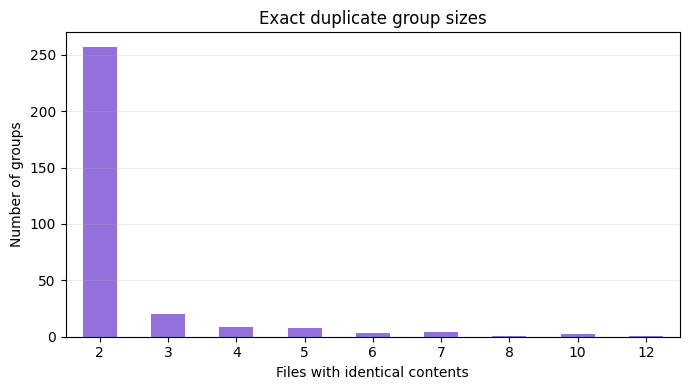

In [7]:
group_sizes = duplicate_groups.apply(len).value_counts().sort_index()
ax = group_sizes.plot.bar(figsize=(7, 4), color="mediumpurple")
ax.set(title="Exact duplicate group sizes", xlabel="Files with identical contents", ylabel="Number of groups")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

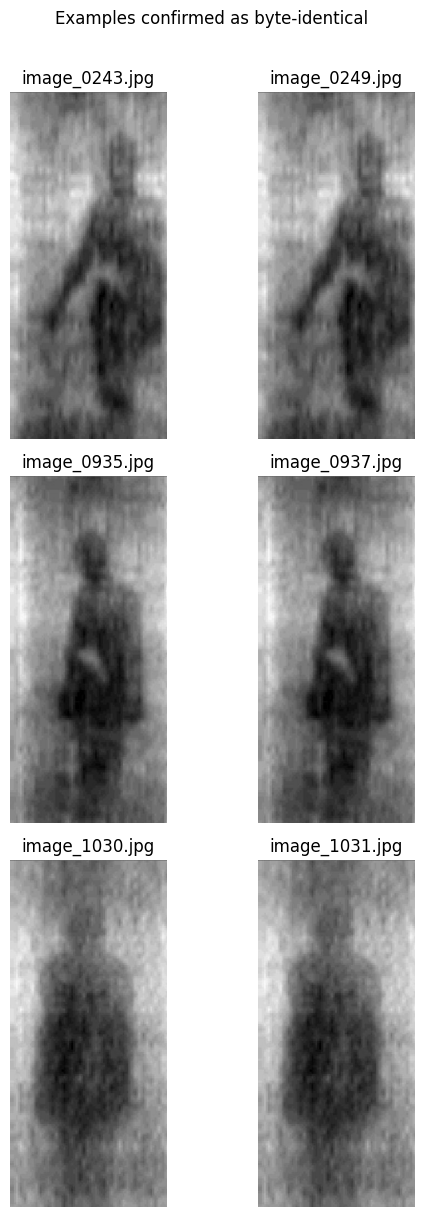

In [8]:
examples = duplicate_groups.head(3).tolist()
if examples:
    fig, axes = plt.subplots(len(examples), 2, figsize=(6, 4 * len(examples)))
    if len(examples) == 1:
        axes = [axes]
    for row, paths in zip(axes, examples):
        for ax, path in zip(row, paths[:2]):
            ax.imshow(Image.open(path), cmap="gray")
            ax.set_title(path.name)
            ax.axis("off")
    fig.suptitle("Examples confirmed as byte-identical", y=1.01)
    plt.tight_layout()
    plt.show()

## 5. Resolve duplicate labels

Select one representative per duplicate group and flag conflicting gun labels for review.

In [9]:
# Find exact duplicates whose gun labels disagree.
duplicate_mask = images["sha256"].isin(duplicate_groups.index)
duplicate_mask = duplicate_mask & images["has_annotation"]
duplicate_rows = images[duplicate_mask]
gun_label_counts = duplicate_rows.groupby("sha256")["has_gun"].nunique()
gun_conflict_hashes = gun_label_counts[gun_label_counts > 1].index.tolist()
gun_conflict_hashes.sort(
    key=lambda value: images.loc[images["sha256"] == value, "image_name"].min()
)

# Choose the best-labelled representative from each exact duplicate group.
automatic_representatives = images.sort_values(
    ["has_annotation", "has_gun", "object_count", "image_name"],
    ascending=[False, False, False, True],
)
automatic_representatives = automatic_representatives.drop_duplicates("sha256")
automatic_representatives = automatic_representatives.sort_values("image_name")
automatic_representatives = automatic_representatives.reset_index(drop=True)

unusual_image_names = set(
    annotations.loc[annotations["class_name"].isin(["cat", "other"]), "image_name"]
)

print(f"Unique image representatives: {len(automatic_representatives)}")
print(f"Gun-label disagreement groups: {len(gun_conflict_hashes)}")


Unique image representatives: 1193
Gun-label disagreement groups: 32


## 6. Review conflicting labels

Inspect and resolve duplicate groups with inconsistent gun labels.

In [10]:
gun_review_groups = []
for group_number, file_hash in enumerate(gun_conflict_hashes, start=1):
    versions = images[images["sha256"] == file_hash].sort_values("image_name")
    gun_review_groups.append({
        "group": group_number,
        "sha256": file_hash,
        "gun_versions": versions.loc[versions["has_gun"], "image_name"].tolist(),
        "no_gun_versions": versions.loc[~versions["has_gun"], "image_name"].tolist(),
    })

print(f"Gun-label disagreement groups ready for review: {len(gun_review_groups)}")


Gun-label disagreement groups ready for review: 32


In [11]:
SHOW_CONFLICT_REVIEW = False
REVIEW_PAGE = 1
GROUPS_PER_PAGE = 4


def draw_annotation_version(ax, image_name):
    ax.imshow(Image.open(IMAGE_DIR / image_name), cmap="gray")
    for _, box in annotations[annotations["image_name"] == image_name].iterrows():
        colour = "red" if box["class_name"] == "gun" else "cyan"
        ax.add_patch(Rectangle(
            (box["xmin"], box["ymin"]), box["box_width"], box["box_height"],
            fill=False, edgecolor=colour, linewidth=2,
        ))
        ax.text(
            box["xmin"], box["ymin"], box["class_name"], color=colour, fontsize=9,
            bbox={"facecolor": "black", "alpha": 0.5, "pad": 1},
        )
    ax.axis("off")


if SHOW_CONFLICT_REVIEW:
    total_pages = (len(gun_review_groups) + GROUPS_PER_PAGE - 1) // GROUPS_PER_PAGE
    if not 1 <= REVIEW_PAGE <= total_pages:
        raise ValueError(f"REVIEW_PAGE must be between 1 and {total_pages}.")

    start = (REVIEW_PAGE - 1) * GROUPS_PER_PAGE
    page_groups = gun_review_groups[start:start + GROUPS_PER_PAGE]
    fig, axes = plt.subplots(
        len(page_groups), 2, figsize=(8, 5 * len(page_groups)), squeeze=False
    )

    for row, group in zip(axes, page_groups):
        gun_example = group["gun_versions"][0]
        no_gun_example = group["no_gun_versions"][0]
        draw_annotation_version(row[0], gun_example)
        draw_annotation_version(row[1], no_gun_example)
        row[0].set_title(f"Group {group['group']}: GUN label\n{gun_example}")
        row[1].set_title(f"Group {group['group']}: NO GUN label\n{no_gun_example}")
        print(
            f"Group {group['group']}: gun = {', '.join(group['gun_versions'])}; "
            f"no gun = {', '.join(group['no_gun_versions'])}"
        )

    fig.suptitle(
        f"Gun-label disagreements - page {REVIEW_PAGE} of {total_pages}", y=1.01
    )
    plt.tight_layout()
    plt.show()


In [12]:
CONFLICT_DECISIONS = {
    1: "gun", 2: "gun", 3: "gun", 4: "no gun", 5: "no gun",
    6: "gun", 7: "gun", 8: "no gun", 9: "no gun", 10: "gun",
    11: "delete", 12: "delete", 13: "gun", 14: "gun", 15: "gun",
    16: "gun", 17: "no gun", 18: "gun", 19: "gun", 20: "gun",
    21: "gun", 22: "no gun", 23: "no gun", 24: "gun", 25: "delete",
    26: "delete", 27: "delete", 28: "no gun", 29: "gun", 30: "no gun",
    31: "no gun", 32: "delete",
}

expected_groups = {group["group"] for group in gun_review_groups}
if set(CONFLICT_DECISIONS) != expected_groups:
    raise ValueError("Conflict decisions must cover every review group exactly once.")

resolved_conflict_images = []
resolution_rows = []

for group in gun_review_groups:
    action = CONFLICT_DECISIONS[group["group"]]
    all_versions = group["gun_versions"] + group["no_gun_versions"]
    kept_image = None

    if action != "delete":
        candidates = group["gun_versions"] if action == "gun" else group["no_gun_versions"]
        kept_image = candidates[0]
        resolved_conflict_images.append(kept_image)

    resolution_rows.append({
        "group": group["group"], "action": action, "kept_image": kept_image,
        "removed_images": len(all_versions) - int(kept_image is not None),
    })

# Replace all conflicting representatives with the reviewed choices.
non_conflict_representatives = automatic_representatives[
    ~automatic_representatives["sha256"].isin(gun_conflict_hashes)
]
reviewed_representatives = images[images["image_name"].isin(resolved_conflict_images)]
representatives = pd.concat(
    [non_conflict_representatives, reviewed_representatives], ignore_index=True
)
representatives = representatives.sort_values("image_name")
representatives = representatives.reset_index(drop=True)

# Exclude the reviewed cat/other images.
removed_unusual = sorted(
    unusual_image_names & set(representatives["image_name"])
)

keep_images = ~representatives["image_name"].isin(removed_unusual)
clean_images = representatives[keep_images].copy()
clean_images = clean_images.reset_index(drop=True)

keep_annotations = annotations["image_name"].isin(clean_images["image_name"])
clean_annotations = annotations[keep_annotations].copy()
clean_annotations = clean_annotations.reset_index(drop=True)

display(pd.DataFrame(resolution_rows))
print(f"Resolved conflict groups: {len(resolved_conflict_images)}")
print(f"Deleted conflict groups:  {sum(action == 'delete' for action in CONFLICT_DECISIONS.values())}")
print(f"Removed cat/other images: {len(removed_unusual)}")
print(f"Clean images:             {len(clean_images)}")
print(f"Clean annotations:        {len(clean_annotations)}")


,group,action,kept_image,removed_images
0,1,gun,image_0028.jpg,1
1,2,gun,image_0067.jpg,1
2,3,gun,image_0115.jpg,1
3,4,no gun,image_0275.jpg,1
4,5,no gun,image_0298.jpg,1
5,6,gun,image_0305.jpg,2
6,7,gun,image_1233.jpg,2
7,8,no gun,image_0442.jpg,1
8,9,no gun,image_0449.jpg,2
9,10,gun,image_0459.jpg,1


Resolved conflict groups: 26
Deleted conflict groups:  6
Removed cat/other images: 23
Clean images:             1164
Clean annotations:        1767


### Additional data filtering

In [13]:
def show_images(image_names, columns=4, show_gun_boxes=False):
    if not image_names:
        print("No image names provided.")
        return

    columns = min(columns, len(image_names))
    rows = (len(image_names) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 6 * rows), squeeze=False)

    for ax, image_name in zip(axes.flat, image_names):
        image_path = IMAGE_DIR / image_name
        if image_path.exists():
            ax.imshow(Image.open(image_path), cmap="gray")
            if show_gun_boxes:
                gun_boxes = annotations[
                    (annotations["image_name"] == image_name)
                    & (annotations["class_name"] == "gun")
                ]
                for box in gun_boxes.itertuples(index=False):
                    ax.add_patch(Rectangle(
                        (box.xmin, box.ymin), box.box_width, box.box_height,
                        fill=False, edgecolor="red", linewidth=2,
                    ))
            ax.set_title(image_name)
        else:
            ax.set_title(f"Missing: {image_name}", color="red")
        ax.axis("off")

    for ax in axes.flat[len(image_names):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def exclude_images(image_table, annotation_table, image_names):
    image_names = set(image_names)
    return (
        image_table[~image_table["image_name"].isin(image_names)].copy().reset_index(drop=True),
        annotation_table[~annotation_table["image_name"].isin(image_names)].copy().reset_index(drop=True),
    )


### Remove anomalous gun boxes

Review gun boxes covering more than 10% of the image and exclude affected images.

,image_name,relative_box_area
1858,image_1207.jpg,79.1%
379,image_0265.jpg,41.7%
1936,image_1248.jpg,7.8%
1918,image_1239.jpg,7.8%
2415,image_1606.jpg,7.6%
2093,image_1365.jpg,7.5%
2091,image_1364.jpg,7.3%
2095,image_1366.jpg,7.1%
471,image_0321.jpg,7.1%
1496,image_0962.jpg,7.1%


,image_name,xmin,ymin,xmax,ymax,relative_box_area
379,image_0265.jpg,101,93,240,631,41.7%
1858,image_1207.jpg,41,1,266,631,79.1%


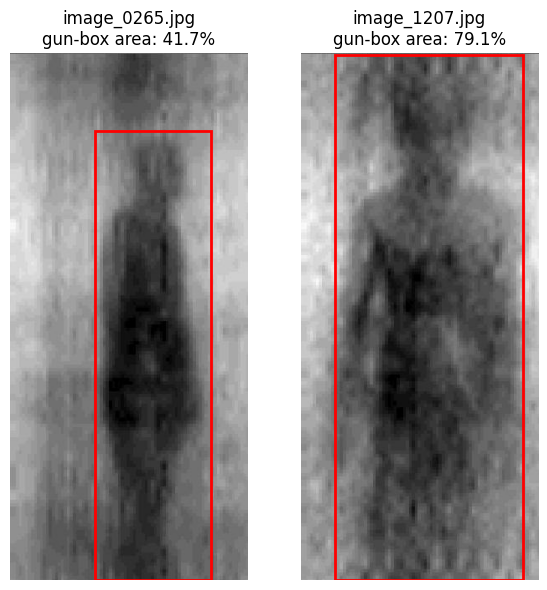

Extreme annotations found: 2
Images removed from the cleaned dataset: []


In [103]:
def show_box_audit(boxes, score_column, score_label, colour):
    image_names = sorted(boxes["image_name"].unique())
    if not image_names:
        print("No images were flagged.")
        return

    columns = min(4, len(image_names))
    rows = (len(image_names) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 6 * rows), squeeze=False)

    for ax, image_name in zip(axes.flat, image_names):
        image_boxes = boxes[boxes["image_name"] == image_name]
        ax.imshow(Image.open(IMAGE_DIR / image_name), cmap="gray")
        for box in image_boxes.itertuples(index=False):
            ax.add_patch(Rectangle(
                (box.xmin, box.ymin), box.box_width, box.box_height,
                fill=False, edgecolor=colour, linewidth=2,
            ))
        score = image_boxes[score_column].max()
        ax.set_title(f"{image_name}\n{score_label}: {score:.1%}")
        ax.axis("off")

    for ax in axes.flat[len(image_names):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


gun_box_areas = annotations.loc[
    annotations["class_name"] == "gun",
    ["image_name", "relative_box_area"],
].nlargest(10, "relative_box_area")
display(gun_box_areas.style.format({"relative_box_area": "{:.1%}"}))


EXTREME_GUN_AREA_LIMIT = 0.10
extreme_gun_boxes = annotations[
    (annotations["class_name"] == "gun")
    & (annotations["relative_box_area"] > EXTREME_GUN_AREA_LIMIT)
].copy()
extreme_gun_images = set(extreme_gun_boxes["image_name"])
removed_extreme_gun_images = sorted(extreme_gun_images & set(clean_images["image_name"]))

display(extreme_gun_boxes[[
    "image_name", "xmin", "ymin", "xmax", "ymax", "relative_box_area"
]].style.format({"relative_box_area": "{:.1%}"}))
show_box_audit(extreme_gun_boxes, "relative_box_area", "gun-box area", "red")

clean_images, clean_annotations = exclude_images(
    clean_images, clean_annotations, extreme_gun_images
)

print(f"Extreme annotations found: {len(extreme_gun_boxes)}")
print(f"Images removed from the cleaned dataset: {removed_extreme_gun_images}")


### Remove images without person annotations

Review and remove images with no person annotation.

Images without a person annotation: ['image_0105.jpg', 'image_0417.jpg', 'image_0419.jpg', 'image_0476.jpg', 'image_0492.jpg', 'image_0504.jpg', 'image_1060.jpg', 'image_1468.jpg']


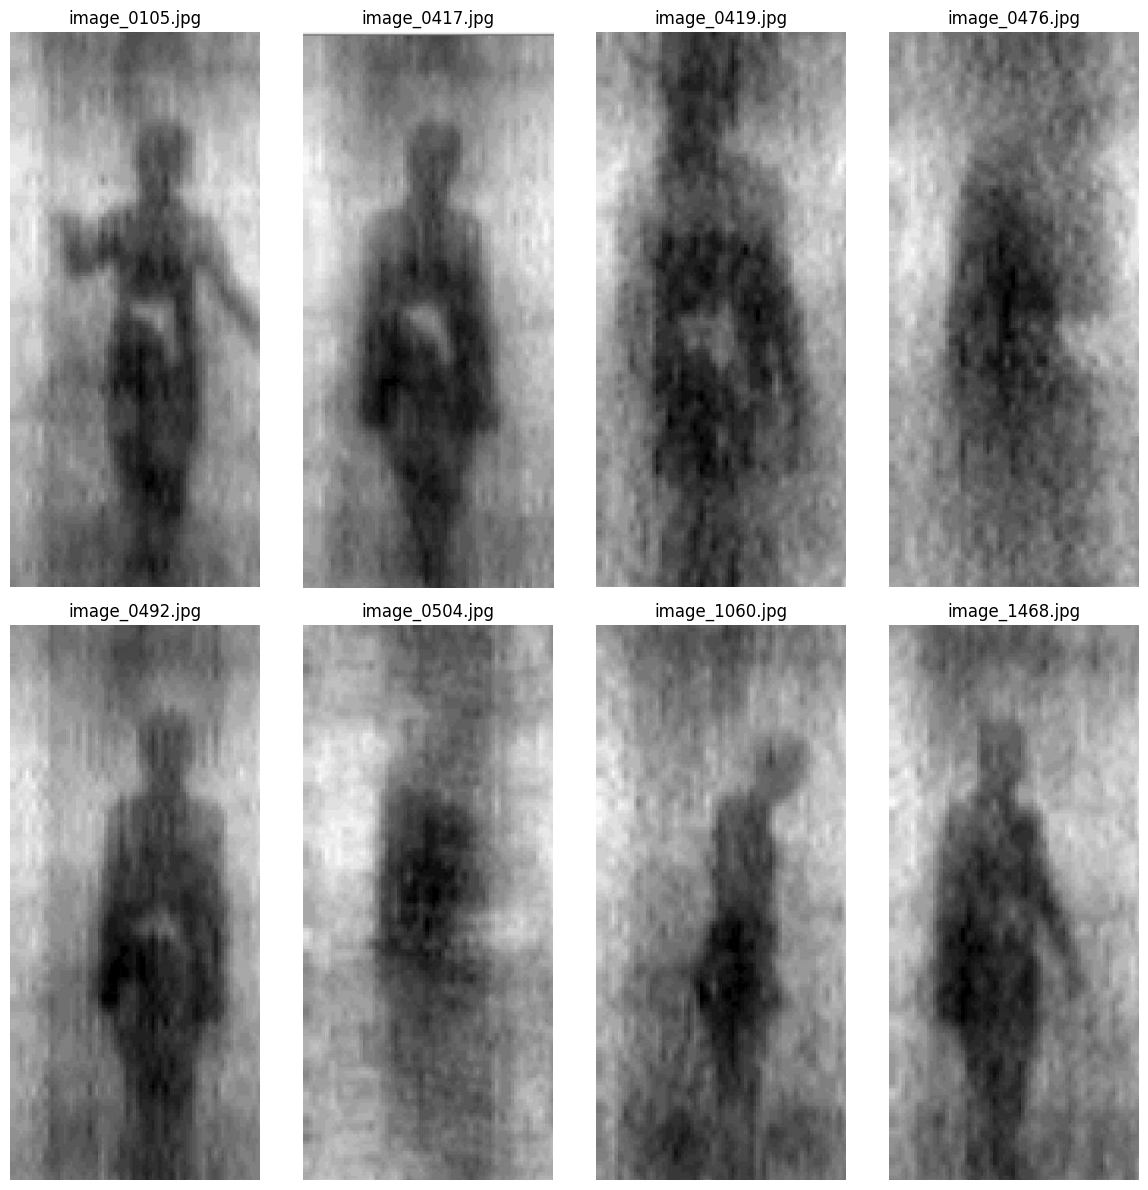

Images without a person annotation removed: 8


In [15]:
person_images = set(
    clean_annotations.loc[clean_annotations["class_name"] == "person", "image_name"]
)
missing_person_images = sorted(
    set(clean_images["image_name"]) - person_images
)

print(f"Images without a person annotation: {missing_person_images}")
show_images(missing_person_images)

clean_images, clean_annotations = exclude_images(
    clean_images, clean_annotations, missing_person_images
)

print(f"Images without a person annotation removed: {len(missing_person_images)}")


### Remove unusable `cat` and `other` samples

Exclude reviewed images labelled `cat` or `other`.

Excluded cat/other images: 23


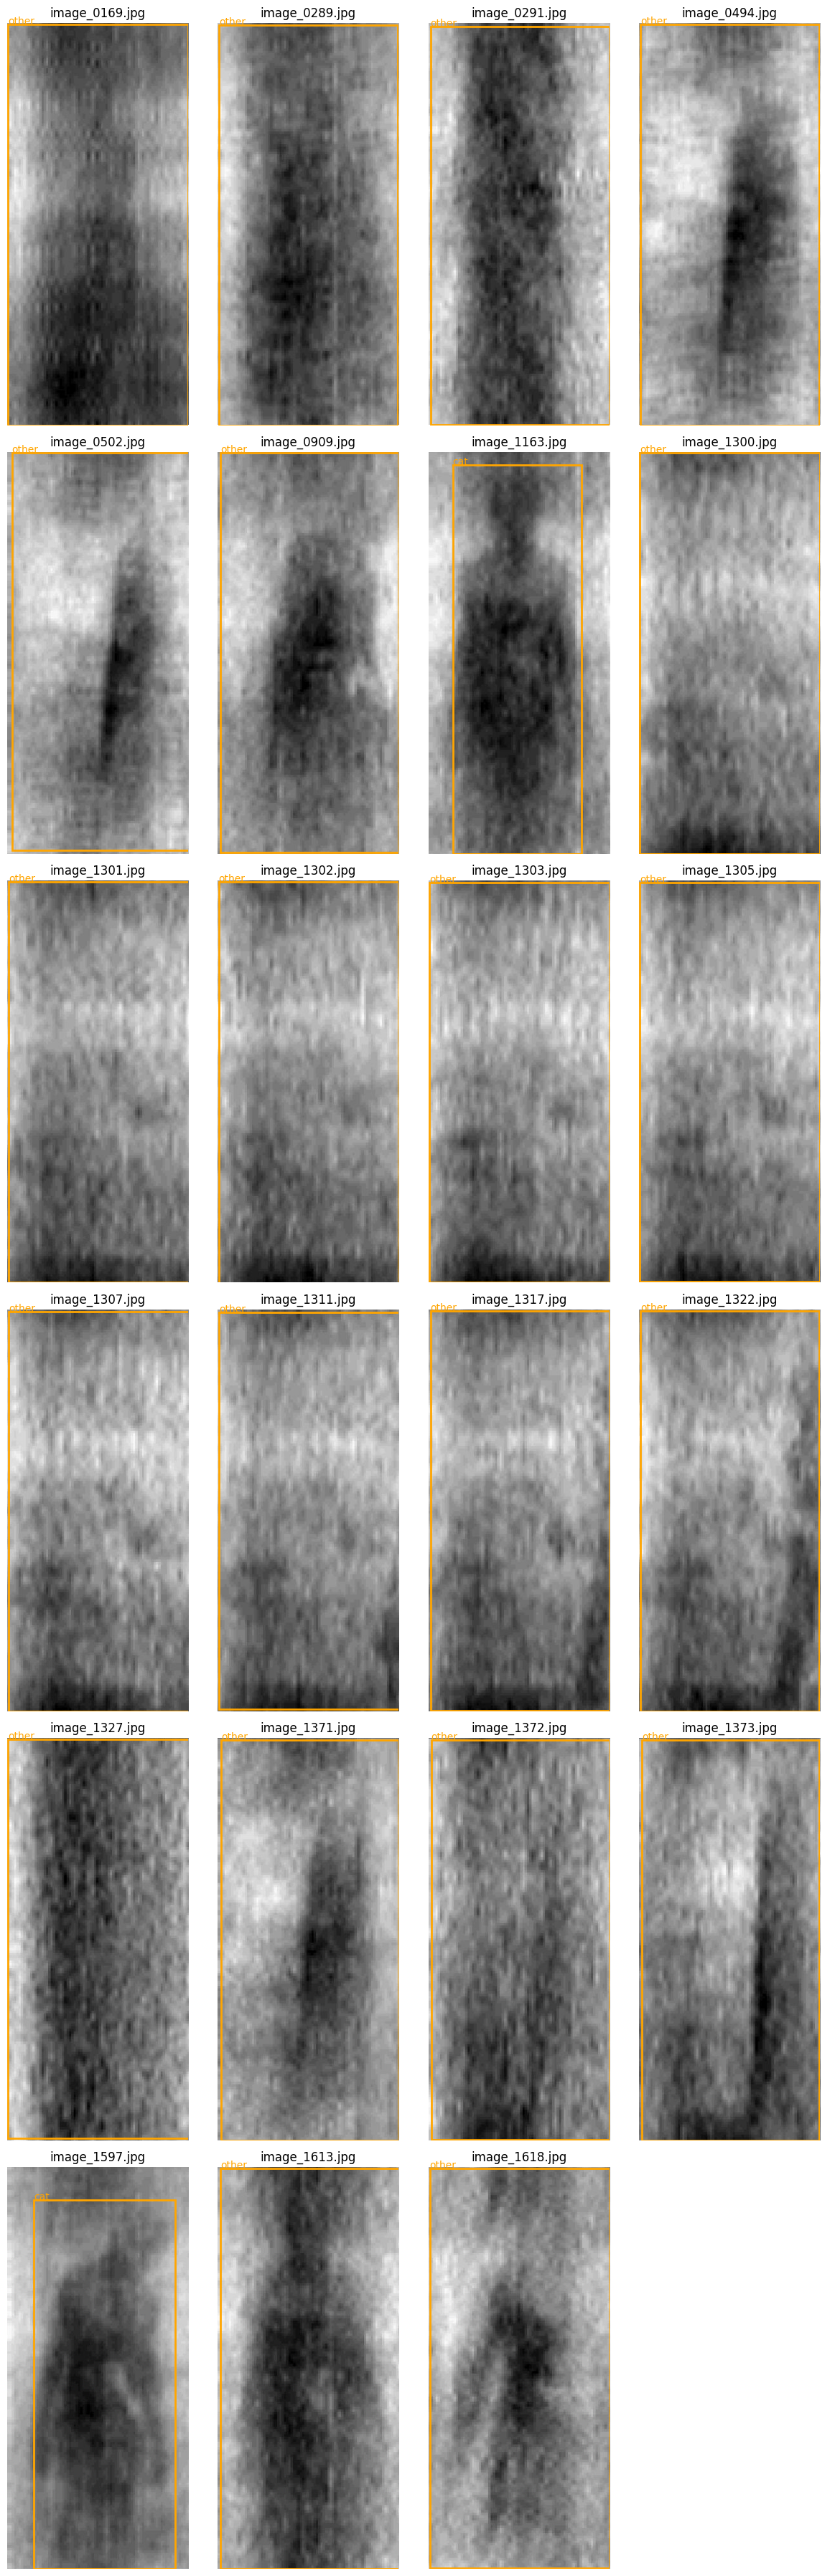

In [16]:
unusual_boxes = annotations[
    annotations["image_name"].isin(removed_unusual)
    & annotations["class_name"].isin(["cat", "other"])
]

print(f"Excluded cat/other images: {len(removed_unusual)}")
if removed_unusual:
    columns = min(4, len(removed_unusual))
    rows = (len(removed_unusual) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 6 * rows), squeeze=False)

    for ax, image_name in zip(axes.flat, removed_unusual):
        ax.imshow(Image.open(IMAGE_DIR / image_name), cmap="gray")
        image_boxes = unusual_boxes[unusual_boxes["image_name"] == image_name]
        for box in image_boxes.itertuples():
            ax.add_patch(Rectangle(
                (box.xmin, box.ymin), box.box_width, box.box_height,
                fill=False, edgecolor="orange", linewidth=2,
            ))
            ax.text(box.xmin, box.ymin, box.class_name, color="orange")
        ax.set_title(image_name)
        ax.axis("off")

    for ax in axes.flat[len(removed_unusual):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


## 7. Define the gun detection task

Retain only gun boxes; gun-free images remain as negative examples.

In [17]:
training_images = clean_images.copy()
gun_annotations = clean_annotations[clean_annotations["class_name"] == "gun"].copy()
gun_annotations = gun_annotations.reset_index(drop=True)
training_images["has_gun"] = training_images["image_name"].isin(gun_annotations["image_name"])

remaining_classes = set(gun_annotations["class_name"])
if remaining_classes != {"gun"}:
    raise AssertionError

annotated_image_names = set(gun_annotations["image_name"])
training_image_names = set(training_images["image_name"])
if not annotated_image_names.issubset(training_image_names):
    raise AssertionError

print(f"Training images:        {len(training_images):,}")
print(f"Gun bounding boxes:     {len(gun_annotations):,}")
print(f"Gun-positive images:    {training_images['has_gun'].sum():,}")
print(f"Negative/background:    {(~training_images['has_gun']).sum():,}")
print("Classes retained:       0: gun")

Training images:        1,155
Gun bounding boxes:     609
Gun-positive images:    609
Negative/background:    546
Classes retained:       0: gun


## 8. Group visually similar images

Use ImageHash to calculate 64-bit perceptual hashes and group near-duplicate frames.

pHash distance:                 <= 1 of 64 bits
Similarity groups:              1,082
Multi-image similarity groups:  45
Images in multi-image groups:   118
Singleton images:               1,037
Largest similarity group:       14 images


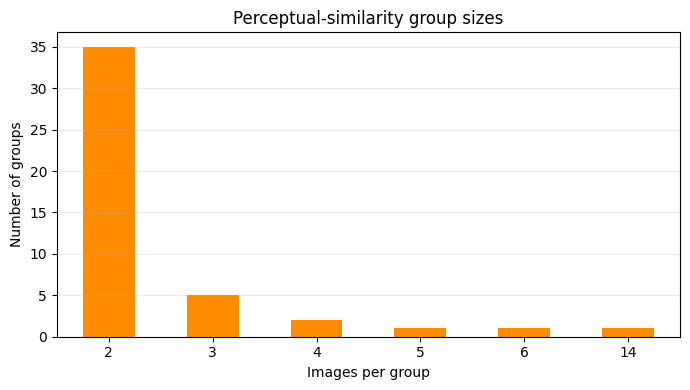

In [18]:
PHASH_MAX_DISTANCE = 1


def calculate_phash(image_path):
    with Image.open(image_path) as image:
        return imagehash.phash(image, hash_size=8)


image_hashes = training_images["image_path"].apply(calculate_phash).tolist()

# Each image starts in its own group. Similar groups are merged below.
group_parent = list(range(len(image_hashes)))


def find_group_root(image_index):
    while group_parent[image_index] != image_index:
        group_parent[image_index] = group_parent[group_parent[image_index]]
        image_index = group_parent[image_index]
    return image_index


for first_index, second_index in combinations(range(len(image_hashes)), 2):
    distance = image_hashes[first_index] - image_hashes[second_index]
    if distance <= PHASH_MAX_DISTANCE:
        first_group = find_group_root(first_index)
        second_group = find_group_root(second_index)
        group_parent[second_group] = first_group

image_roots = [find_group_root(index) for index in range(len(image_hashes))]
unique_roots = sorted(set(image_roots))
group_names = {
    root: f"similarity_{number:04d}"
    for number, root in enumerate(unique_roots)
}
training_images["similarity_group"] = [group_names[root] for root in image_roots]

similarity_group_sizes = training_images.groupby("similarity_group").size()
similarity_group_sizes = similarity_group_sizes.sort_values(ascending=False)
near_duplicate_groups = similarity_group_sizes[similarity_group_sizes > 1]

print(f"pHash distance:                 <= {PHASH_MAX_DISTANCE} of 64 bits")
print(f"Similarity groups:              {len(similarity_group_sizes):,}")
print(f"Multi-image similarity groups:  {len(near_duplicate_groups):,}")
print(f"Images in multi-image groups:   {near_duplicate_groups.sum():,}")
print(f"Singleton images:               {(similarity_group_sizes == 1).sum():,}")
print(f"Largest similarity group:       {similarity_group_sizes.max():,} images")

group_size_counts = near_duplicate_groups.value_counts().sort_index()
ax = group_size_counts.plot.bar(figsize=(7, 4), color="darkorange")
ax.set(
    title="Perceptual-similarity group sizes",
    xlabel="Images per group",
    ylabel="Number of groups",
)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

similarity_0000: 14 visually similar images
Maximum pairwise pHash distance: 0 bits (transitive chaining: no)


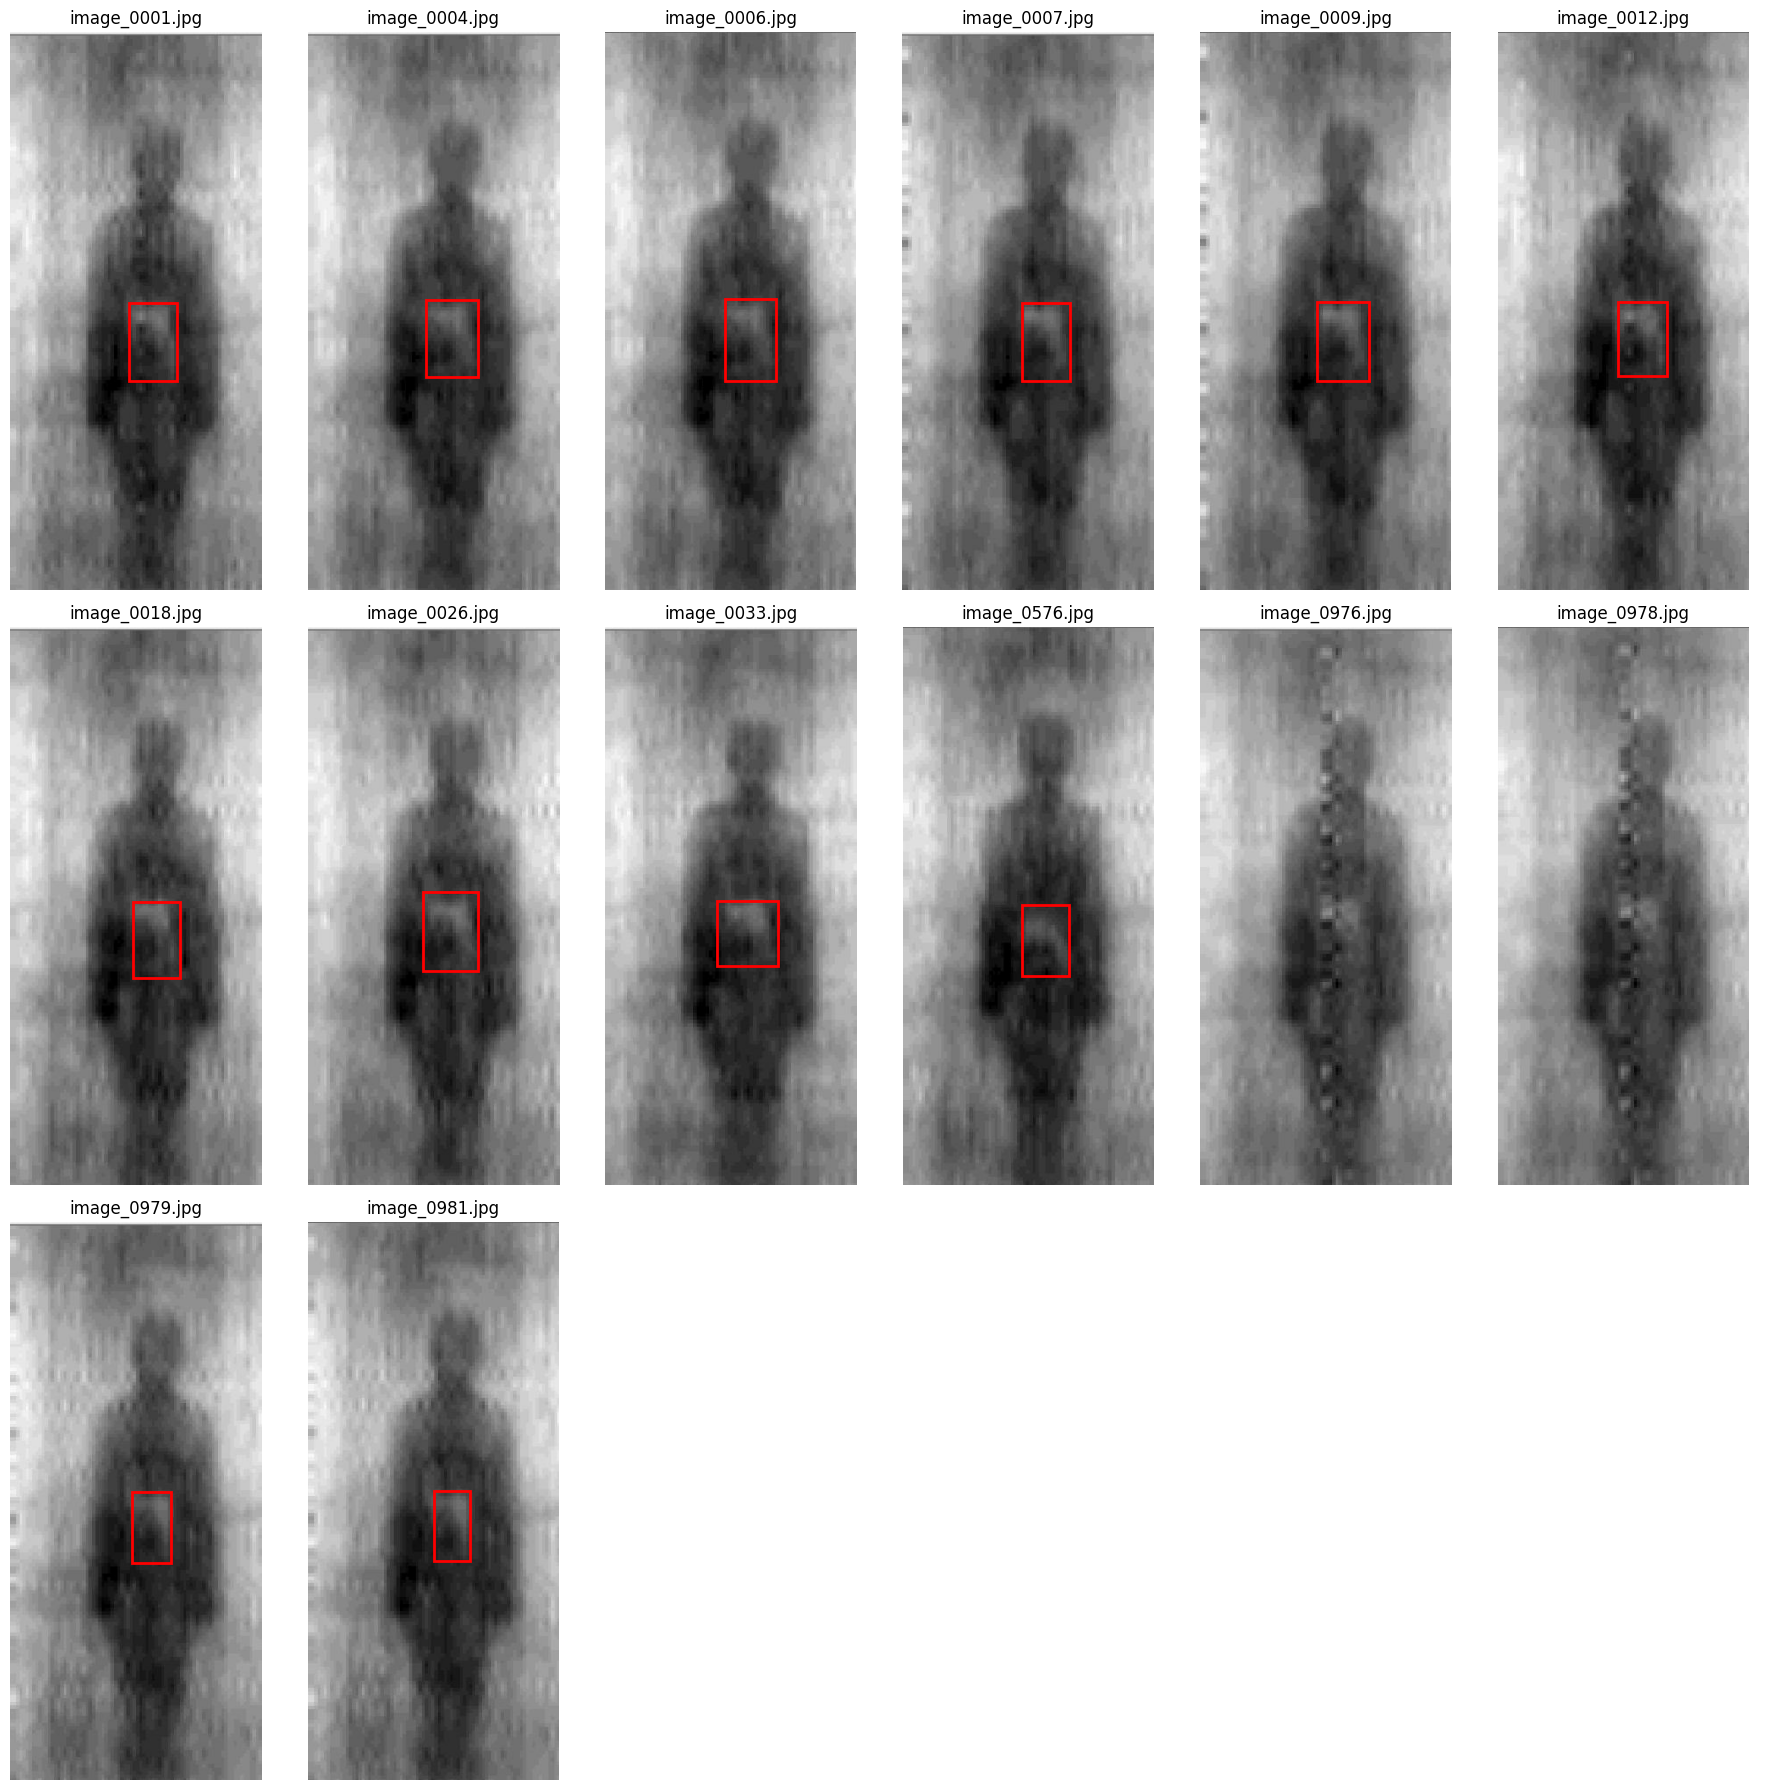

In [19]:
NEAR_DUPLICATE_REVIEW_GROUP = 1

group_id = near_duplicate_groups.index[NEAR_DUPLICATE_REVIEW_GROUP - 1]
group_images = training_images.loc[
    training_images["similarity_group"] == group_id, "image_name"
].tolist()
image_indices = np.flatnonzero(
    training_images["similarity_group"].eq(group_id).to_numpy()
)

pairwise_distances = []
for first_index, second_index in combinations(image_indices, 2):
    distance = image_hashes[first_index] - image_hashes[second_index]
    pairwise_distances.append(distance)

maximum_pairwise_distance = max(pairwise_distances, default=0)
has_transitive_chaining = maximum_pairwise_distance > PHASH_MAX_DISTANCE

print(f"{group_id}: {len(group_images)} visually similar images")
print(
    f"Maximum pairwise pHash distance: {maximum_pairwise_distance} bits "
    f"(transitive chaining: {'yes' if has_transitive_chaining else 'no'})"
)
show_images(
    group_images, columns=min(6, len(group_images)), show_gun_boxes=True
)

## 9. Create group-aware data splits

Create 70/15/15 train, validation and test splits while keeping each similarity group together.

In [20]:
splitter = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
training_images["fold"] = -1

for fold, (_, indices) in enumerate(splitter.split(
    training_images, training_images["has_gun"], training_images["similarity_group"]
)):
    training_images.loc[training_images.index[indices], "fold"] = fold

training_images["split"] = "train"
training_images.loc[training_images["fold"].isin([0, 1, 2]), "split"] = "val"
training_images.loc[training_images["fold"].isin([3, 4, 5]), "split"] = "test"

group_split_counts = training_images.groupby("similarity_group")["split"].nunique()
if group_split_counts.max() != 1:
    raise AssertionError

split_statistics = training_images.groupby("split").agg(
    images=("image_name", "size"),
    gun_positive=("has_gun", "sum"),
    similarity_groups=("similarity_group", "nunique"),
)
split_statistics = split_statistics.reindex(["train", "val", "test"])

split_statistics["gun_negative"] = split_statistics["images"] - split_statistics["gun_positive"]
display(split_statistics)

,images,gun_positive,similarity_groups,gun_negative
split,,,,
train,807,426,768,381
val,174,91,152,83
test,174,92,162,82


## 10. Convert annotations to YOLO format

Write normalised single-class labels; negative images receive empty label files.

In [21]:
OUTPUT_ROOT = DATASET_ROOT.parent / "processed"
boxes_by_image = {name: boxes for name, boxes in gun_annotations.groupby("image_name")}

for split in ("train", "val", "test"):
    image_folder = OUTPUT_ROOT / "images" / split
    label_folder = OUTPUT_ROOT / "labels" / split
    image_folder.mkdir(parents=True, exist_ok=True)
    label_folder.mkdir(parents=True, exist_ok=True)

    for old_file in [*image_folder.glob("*"), *label_folder.glob("*")]:
        old_file.unlink()

    for image in training_images[training_images["split"] == split].itertuples(index=False):
        shutil.copy2(image.image_path, image_folder / image.image_name)
        boxes = boxes_by_image.get(image.image_name, pd.DataFrame())
        lines = [
            f"0 {(box.xmin + box.xmax) / (2 * box.width):.6f} "
            f"{(box.ymin + box.ymax) / (2 * box.height):.6f} "
            f"{(box.xmax - box.xmin) / box.width:.6f} "
            f"{(box.ymax - box.ymin) / box.height:.6f}"
            for box in boxes.itertuples(index=False)
        ]
        (label_folder / f"{Path(image.image_name).stem}.txt").write_text("\n".join(lines))

manifest_columns = ["image_name", "split", "has_gun", "similarity_group", "sha256"]
training_images[manifest_columns].to_csv(OUTPUT_ROOT / "split_manifest.csv", index=False)

dataset_yaml = f'''path: "{OUTPUT_ROOT.resolve().as_posix()}"
train: images/train
val: images/val
test: images/test
names:
  0: gun
'''
(OUTPUT_ROOT / "dataset.yaml").write_text(dataset_yaml, encoding="utf-8")
print(f"YOLO dataset created at: {OUTPUT_ROOT.resolve()}")

YOLO dataset created at: C:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed


## 11. Select the training configuration

Use validation results to select augmentation, input resolution and pretrained initialisation. Keep the test set untouched.

In [ ]:
SKIP_ALL_EXPERIMENTS = True
RUN_EXPERIMENTS = {
    1: True, 2: True,
    3: True, 4: True,
    5: True, 6: True, 7: True, 8: True, 9: True,
}
RUN_REPEATABILITY_EXPERIMENT = True
RUN_CROSS_VALIDATION_EXPERIMENT = True  # Enable after choosing one final model

if SKIP_ALL_EXPERIMENTS:
    RUN_EXPERIMENTS = {number: False for number in RUN_EXPERIMENTS}
    RUN_REPEATABILITY_EXPERIMENT = False
    RUN_CROSS_VALIDATION_EXPERIMENT = False


In [82]:
ULTRALYTICS_VERSION = "8.4.120"
CHECKPOINT_SHA256 = {
    "yolov8n.pt": "f59b3d833e2ff32e194b5bb8e08d211dc7c5bdf144b90d2c8412c47ccfc83b36",
    "yolo11n.pt": "0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1",
    "yolo11s.pt": "85a76fe86dd8afe384648546b56a7a78580c7cb7b404fc595f97969322d502d5",
    "yolo26n.pt": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef",
    "yolo26s.pt": "646f8bc3fe0a656803d95c294f7852321748cb29d13466a1af8862e2db384a1b",
}
MODEL_FILES = {
    "yolov8n": ("yolov8n.pt", "yolov8n.yaml"),
    "yolo11n": ("yolo11n.pt", "yolo11n.yaml"),
    "yolo11s": ("yolo11s.pt", "yolo11s.yaml"),
    "yolo26n": ("yolo26n.pt", "yolo26n.yaml"),
    "yolo26s": ("yolo26s.pt", "yolo26s.yaml"),
}

NO_AUGMENTATION = dict(
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=0.0, translate=0.0,
    scale=0.0, shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.0,
    bgr=0.0, mosaic=0.0, mixup=0.0, cutmix=0.0, copy_paste=0.0,
)
PMMW_AUGMENTATION = {
    **NO_AUGMENTATION,
    "hsv_v": 0.10, "degrees": 3.0, "translate": 0.05,
    "scale": 0.15, "fliplr": 0.5,
}
AUGMENTATIONS = {"none": NO_AUGMENTATION, "pmmw": PMMW_AUGMENTATION}

if ultralytics.__version__ != ULTRALYTICS_VERSION:
    raise RuntimeError(
        f"Expected ultralytics {ULTRALYTICS_VERSION}, found {ultralytics.__version__}."
    )

RESULTS_ROOT = (DATASET_ROOT.parent / "results").resolve()


def verify_checkpoint(filename):
    path = Path(filename)
    if not path.exists():
        raise FileNotFoundError(f"Pinned checkpoint not found: {path.resolve()}")
    if sha256_file(path) != CHECKPOINT_SHA256[path.name]:
        raise ValueError(f"Checkpoint hash does not match: {path.name}")
    return path


def clear_previous_run(folder):
    run_folder = (RESULTS_ROOT / folder).resolve()
    if RESULTS_ROOT not in run_folder.parents:
        raise ValueError(f"Unsafe results path: {run_folder}")
    if run_folder.exists():
        shutil.rmtree(run_folder)
        print(f"Deleted previous results: {run_folder}")


def model_source(model_key, pretrained):
    pretrained_file, scratch_file = MODEL_FILES[model_key]
    return verify_checkpoint(pretrained_file) if pretrained else scratch_file


def train_detector(
    model_key, folder, augmentation, imgsz, pretrained, batch=64, seed=SEED, data_yaml=None,
):
    clear_previous_run(folder)
    epochs, patience = (100, 30) if pretrained else (200, 30)

    start = time.perf_counter()
    model = YOLO(model_source(model_key, pretrained))
    model.train(
        data=str(data_yaml or OUTPUT_ROOT / "dataset.yaml"),
        epochs=epochs, patience=patience,
        imgsz=imgsz, batch=batch, workers=2, device=0, cache="disk", seed=seed,
        pretrained=pretrained, optimizer="AdamW", lr0=0.002, momentum=0.9,
        project=str(RESULTS_ROOT / folder), name="train",
        verbose=False, plots=False, augmentations=[], **AUGMENTATIONS[augmentation],
    )
    training_minutes = (time.perf_counter() - start) / 60
    del model
    gc.collect()
    torch.cuda.empty_cache()
    (RESULTS_ROOT / folder / "training_time_minutes.txt").write_text(
        f"{training_minutes:.6f}", encoding="utf-8"
    )
    print(f"Training time: {training_minutes:.1f} minutes")
    return RESULTS_ROOT / folder / "train" / "weights" / "best.pt"


def run_experiment(config):
    checkpoint = RESULTS_ROOT / config["folder"] / "train" / "weights" / "best.pt"
    if config.get("reuse"):
        if not checkpoint.exists():
            raise FileNotFoundError(f"Run the matching earlier experiment first: {checkpoint}")
        print(f"Experiment {config['number']} reuses: {checkpoint}")
        return checkpoint
    return train_detector(
        config["model"], config["folder"], config["augmentation"],
        config["imgsz"], config["pretrained"],
    )


In [94]:
RESULT_FORMATS = {
    "AP50": "{:.3f}", "mAP50-95": "{:.3f}", "Precision": "{:.3f}",
    "Recall": "{:.3f}", "F1": "{:.3f}",
    "Parameters (M)": "{:.2f}", "GFLOPs": "{:.1f}",
}
COMPARISON_CACHE = {}


def compare_detector(config):
    run_folder = RESULTS_ROOT / config["folder"]
    checkpoint = run_folder / "train" / "weights" / "best.pt"
    model = YOLO(checkpoint)
    gflops = model.info(imgsz=config["imgsz"])[-1]
    metrics = model.val(
        data=str(OUTPUT_ROOT / "dataset.yaml"), split="val", imgsz=config["imgsz"],
        device=0, project=str(run_folder), name="val", exist_ok=True,
        plots=True, verbose=False, workers=0
    )

    precision, recall = metrics.box.mp, metrics.box.mr
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    history = pd.read_csv(run_folder / "train" / "results.csv")
    best_row = history.loc[history["metrics/mAP50-95(B)"].idxmax()]
    best_epoch_time = f"{int(best_row['epoch'])} ({best_row['time'] / 60:.1f} min)"

    result = {
        "AP50": metrics.box.map50, "mAP50-95": metrics.box.map,
        "Precision": precision, "Recall": recall, "F1": f1,
        "Best epoch (time)": best_epoch_time,
        "Parameters (M)": sum(p.numel() for p in model.model.parameters()) / 1e6,
        "GFLOPs": gflops,
    }
    del metrics, model
    gc.collect()
    torch.cuda.empty_cache()
    return result


def display_experiment_results(configs, filename=None):
    rows = [] 
    for config in configs:
        checkpoint = RESULTS_ROOT / config["folder"] / "train" / "weights" / "best.pt"
        if not checkpoint.exists():
            continue
        cache_key = (str(checkpoint), checkpoint.stat().st_mtime_ns, config["imgsz"])
        if cache_key not in COMPARISON_CACHE:
            with capture_output():
                COMPARISON_CACHE[cache_key] = compare_detector(config)
        rows.append({
            "Experiment": f"{config['number']}. {config['name']}",
            **COMPARISON_CACHE[cache_key],
        })

    if not rows:
        print("No completed checkpoints found for this comparison.")
        return None

    table = pd.DataFrame(rows).set_index("Experiment")
    if filename:
        table.to_csv(RESULTS_ROOT / filename)
    display(table.style.format(RESULT_FORMATS).highlight_max(
        subset=["AP50", "mAP50-95", "Precision", "Recall", "F1"], color="green"
    ).highlight_min(subset=["Parameters (M)", "GFLOPs"], color="green"))
    return table


### Experiment 1: YOLO11-Nano without augmentation

Baseline: pretrained YOLO11n at 640 × 640 with augmentation disabled.

In [26]:
experiment_1_config = dict(
    number=1, name="YOLO11n — no augmentation", model="yolo11n",
    augmentation="none", imgsz=640, pretrained=True,
    folder="experiment_1_yolo11n_no_aug_640",
)
if RUN_EXPERIMENTS[1]:
    run_experiment(experiment_1_config)


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det

### Experiment 2: YOLO11-Nano with PMMW augmentation

Change only augmentation by applying the PMMW-specific pipeline.

In [27]:
experiment_2_config = dict(
    number=2, name="YOLO11n — PMMW augmentation", model="yolo11n",
    augmentation="pmmw", imgsz=640, pretrained=True,
    folder="experiment_2_yolo11n_pmmw_640",
)
if RUN_EXPERIMENTS[2]:
    run_experiment(experiment_2_config)


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det

#### Select augmentation

Compare validation results, then set `SELECTED_AUGMENTATION`.

In [95]:
augmentation_results = display_experiment_results(
    [experiment_1_config, experiment_2_config], "augmentation_comparison.csv"
)


YOLO11n summary: 182 layers, 2,590,035 parameters, 0 gradients, 6.5 GFLOPs
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 83.122.2 MB/s, size: 18.1 KB)
                   all        174         91      0.841      0.868      0.931      0.514
Speed: 0.2ms preprocess, 1.1ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to C:\Users\ADAM-\Desktop\MSc Major Project\CWD\results\experiment_1_yolo11n_no_aug_640\val
YOLO11n summary: 182 layers, 2,590,035 parameters, 0 gradients, 6.5 GFLOPs
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 141.860.0 MB/s, size: 17.7 KB)
                   all        174         91    

,AP50,mAP50-95,Precision,Recall,F1,Best epoch (time),Parameters (M),GFLOPs
Experiment,,,,,,,,
1. YOLO11n — no augmentation,0.931,0.514,0.841,0.868,0.854,10 (0.6 min),2.58,6.5
2. YOLO11n — PMMW augmentation,0.948,0.564,0.893,0.912,0.903,43 (2.1 min),2.58,6.5


In [29]:
SELECTED_AUGMENTATION = "pmmw"  # "none" or "pmmw"


### Experiment 3: selected augmentation at 512 px

Change only resolution by training the selected pipeline at 512 × 512.

In [30]:
experiment_3_config = dict(
    number=3, name="YOLO11n — selected augmentation at 512", model="yolo11n",
    augmentation=SELECTED_AUGMENTATION, imgsz=512, pretrained=True,
    folder="experiment_3_yolo11n_512",
)
if RUN_EXPERIMENTS[3]:
    run_experiment(experiment_3_config)


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det

#### Select input resolution

Compare 512 × 512 with the matching 640 × 640 run, then set `SELECTED_IMAGE_SIZE`.

In [96]:
matching_640_config = (
    experiment_1_config if SELECTED_AUGMENTATION == "none" else experiment_2_config
)
resolution_results = display_experiment_results(
    [matching_640_config, experiment_3_config], "resolution_comparison.csv"
)


YOLO11n summary: 182 layers, 2,590,035 parameters, 0 gradients, 4.1 GFLOPs
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 181.582.9 MB/s, size: 18.0 KB)
                   all        174         91      0.867      0.945      0.961      0.573
Speed: 0.1ms preprocess, 1.1ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to C:\Users\ADAM-\Desktop\MSc Major Project\CWD\results\experiment_3_yolo11n_512\val


,AP50,mAP50-95,Precision,Recall,F1,Best epoch (time),Parameters (M),GFLOPs
Experiment,,,,,,,,
2. YOLO11n — PMMW augmentation,0.948,0.564,0.893,0.912,0.903,43 (2.1 min),2.58,6.5
3. YOLO11n — selected augmentation at 512,0.961,0.573,0.867,0.945,0.904,43 (1.7 min),2.58,4.1


In [32]:
SELECTED_IMAGE_SIZE = 512  # 512 or 640


### Experiment 4: selected YOLO11-Nano pipeline from scratch

Change only weight initialisation by training the selected pipeline from scratch.

In [33]:
experiment_4_config = dict(
    number=4, name="YOLO11n — selected pipeline from scratch", model="yolo11n",
    augmentation=SELECTED_AUGMENTATION, imgsz=SELECTED_IMAGE_SIZE, pretrained=False,
    folder="experiment_4_yolo11n_scratch",
)
if RUN_EXPERIMENTS[4]:
    run_experiment(experiment_4_config)


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det

#### Select weight initialisation

Compare pretrained and scratch runs, then set `SELECTED_PRETRAINING`.

In [98]:
matching_pretrained_config = (
    experiment_3_config if SELECTED_IMAGE_SIZE == 512 else matching_640_config
)
pretraining_results = display_experiment_results(
    [matching_pretrained_config, experiment_4_config], "pretraining_comparison.csv"
)


,AP50,mAP50-95,Precision,Recall,F1,Best epoch (time),Parameters (M),GFLOPs
Experiment,,,,,,,,
3. YOLO11n — selected augmentation at 512,0.961,0.573,0.867,0.945,0.904,43 (1.7 min),2.58,4.1
4. YOLO11n — selected pipeline from scratch,0.954,0.562,0.849,0.923,0.884,101 (3.6 min),2.58,4.1


In [35]:
SELECTED_PRETRAINING = True  # True or False


## 12. Compare lightweight models

Lock the selected pipeline and compare five lightweight YOLO architectures.

### Experiment 5: YOLOv8-Nano

Older nano baseline.

In [36]:
experiment_5_config = dict(
    number=5, name="YOLOv8n — locked pipeline", model="yolov8n",
    augmentation=SELECTED_AUGMENTATION, imgsz=SELECTED_IMAGE_SIZE,
    pretrained=SELECTED_PRETRAINING, folder="experiment_5_yolov8n_locked",
)
if RUN_EXPERIMENTS[5]:
    run_experiment(experiment_5_config)


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det

### Experiment 6: YOLO11-Nano

Selected YOLO11n reference; reuse its existing checkpoint.

In [37]:
if not SELECTED_PRETRAINING:
    selected_yolo11n_config = experiment_4_config
elif SELECTED_IMAGE_SIZE == 512:
    selected_yolo11n_config = experiment_3_config
else:
    selected_yolo11n_config = matching_640_config

experiment_6_config = {
    **selected_yolo11n_config,
    "number": 6, "name": "YOLO11n — locked pipeline", "reuse": True,
}
if RUN_EXPERIMENTS[6]:
    run_experiment(experiment_6_config)


Experiment 6 reuses: C:\Users\ADAM-\Desktop\MSc Major Project\CWD\results\experiment_3_yolo11n_512\train\weights\best.pt


### Experiment 7: YOLO11-Small

Larger YOLO11 variant.

In [38]:
experiment_7_config = dict(
    number=7, name="YOLO11s — locked pipeline", model="yolo11s",
    augmentation=SELECTED_AUGMENTATION, imgsz=SELECTED_IMAGE_SIZE,
    pretrained=SELECTED_PRETRAINING, folder="experiment_7_yolo11s_locked",
)
if RUN_EXPERIMENTS[7]:
    run_experiment(experiment_7_config)


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det

### Experiment 8: YOLO26-Nano

Newer nano variant with the lowest computational demand.

In [39]:
experiment_8_config = dict(
    number=8, name="YOLO26n — locked pipeline", model="yolo26n",
    augmentation=SELECTED_AUGMENTATION, imgsz=SELECTED_IMAGE_SIZE,
    pretrained=SELECTED_PRETRAINING, folder="experiment_8_yolo26n_locked",
)
if RUN_EXPERIMENTS[8]:
    run_experiment(experiment_8_config)


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det

### Experiment 9: YOLO26-Small

Larger YOLO26 variant.

In [40]:
experiment_9_config = dict(
    number=9, name="YOLO26s — locked pipeline", model="yolo26s",
    augmentation=SELECTED_AUGMENTATION, imgsz=SELECTED_IMAGE_SIZE,
    pretrained=SELECTED_PRETRAINING, folder="experiment_9_yolo26s_locked",
)
if RUN_EXPERIMENTS[9]:
    run_experiment(experiment_9_config)


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=processed\dataset.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det

## 13. Compare validation results

Compare detection metrics, parameters and GFLOPs using validation data only.

In [97]:
results_table = display_experiment_results(
    [
        experiment_1_config, experiment_2_config, experiment_3_config,
        experiment_4_config, experiment_5_config, experiment_6_config,
        experiment_7_config, experiment_8_config, experiment_9_config,
    ],
    "model_comparison.csv",
)


YOLO11n summary: 182 layers, 2,590,035 parameters, 0 gradients, 4.1 GFLOPs
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 158.481.3 MB/s, size: 18.0 KB)
                   all        174         91      0.849      0.923      0.954      0.562
Speed: 0.1ms preprocess, 0.9ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to C:\Users\ADAM-\Desktop\MSc Major Project\CWD\results\experiment_4_yolo11n_scratch\val
Model summary: 130 layers, 3,011,043 parameters, 0 gradients, 5.2 GFLOPs
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 202.7103.4 MB/s, size: 18.3 KB)
                   all        174         91       0.9

,AP50,mAP50-95,Precision,Recall,F1,Best epoch (time),Parameters (M),GFLOPs
Experiment,,,,,,,,
1. YOLO11n — no augmentation,0.931,0.514,0.841,0.868,0.854,10 (0.6 min),2.58,6.5
2. YOLO11n — PMMW augmentation,0.948,0.564,0.893,0.912,0.903,43 (2.1 min),2.58,6.5
3. YOLO11n — selected augmentation at 512,0.961,0.573,0.867,0.945,0.904,43 (1.7 min),2.58,4.1
4. YOLO11n — selected pipeline from scratch,0.954,0.562,0.849,0.923,0.884,101 (3.6 min),2.58,4.1
5. YOLOv8n — locked pipeline,0.951,0.574,0.940,0.859,0.898,56 (1.7 min),3.01,5.2
6. YOLO11n — locked pipeline,0.961,0.573,0.867,0.945,0.904,43 (1.7 min),2.58,4.1
7. YOLO11s — locked pipeline,0.950,0.572,0.851,0.943,0.895,66 (4.0 min),9.41,13.8
8. YOLO26n — locked pipeline,0.957,0.572,0.874,0.912,0.893,18 (0.8 min),2.38,3.7
9. YOLO26s — locked pipeline,0.959,0.563,0.915,0.912,0.913,52 (3.6 min),9.47,14.5


## 14. Check repeatability

Reuse seed 42, train seeds 43 and 44, and report the validation mean and standard deviation.

In [43]:
# Replace after the validation/deployment comparison; keep one or two names.
FINAL_CANDIDATES = ["YOLO11-Nano"]

REPEAT_SEEDS = [42, 43, 44]
FINAL_MODEL_CONFIGS = {
    "YOLOv8-Nano": experiment_5_config,
    "YOLO11-Nano": experiment_6_config,
    "YOLO11-Small": experiment_7_config,
    "YOLO26-Nano": experiment_8_config,
    "YOLO26-Small": experiment_9_config,
}
REPEAT_METRICS = ["AP50", "mAP50-95", "Precision", "Recall", "F1", "Training time (min)"]

if RUN_REPEATABILITY_EXPERIMENT:
    if not 1 <= len(FINAL_CANDIDATES) <= 2:
        raise ValueError("Choose one or two FINAL_CANDIDATES.")
    if any(name not in FINAL_MODEL_CONFIGS for name in FINAL_CANDIDATES):
        raise ValueError("FINAL_CANDIDATES contains an unknown model name.")

    rows = []
    for model_name in FINAL_CANDIDATES:
        config = FINAL_MODEL_CONFIGS[model_name]
        for seed in REPEAT_SEEDS:
            if seed == SEED:
                folder = Path(config["folder"])
                checkpoint = RESULTS_ROOT / folder / "train" / "weights" / "best.pt"
                if not checkpoint.exists():
                    raise FileNotFoundError(f"Seed 42 locked run not found: {checkpoint}")
            else:
                folder = Path("repeatability") / config["model"] / f"seed_{seed}"
                checkpoint = train_detector(
                    config["model"], folder, config["augmentation"], config["imgsz"],
                    config["pretrained"], seed=seed,
                )

            run_folder = RESULTS_ROOT / folder
            metrics = YOLO(checkpoint).val(
                data=str(OUTPUT_ROOT / "dataset.yaml"), split="val", imgsz=config["imgsz"],
                device=0, project=str(run_folder), name="val", exist_ok=True,
                plots=False, verbose=False,
            )
            precision, recall = metrics.box.mp, metrics.box.mr
            f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
            training_minutes = float((run_folder / "training_time_minutes.txt").read_text())
            rows.append({
                "Model": model_name, "Seed": seed,
                "AP50": metrics.box.map50, "mAP50-95": metrics.box.map,
                "Precision": precision, "Recall": recall, "F1": f1,
                "Training time (min)": training_minutes,
            })

    repeat_results = pd.DataFrame(rows)
    repeat_summary = repeat_results.groupby("Model")[REPEAT_METRICS].agg(["mean", "std"])
    output_folder = RESULTS_ROOT / "repeatability"
    output_folder.mkdir(parents=True, exist_ok=True)
    repeat_results.to_csv(output_folder / "runs.csv", index=False)
    repeat_summary.to_csv(output_folder / "summary.csv")
    display(repeat_summary.style.format("{:.3f}"))
else:
    print("Repeatability skipped until final candidates are selected.")


Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 318.457.8 MB/s, size: 18.1 KB)
val: Scanning C:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed\labels\val.cache... 174 images, 83 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 174/174 91.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 24.8it/s 0.4s.1s
                   all        174         91      0.867      0.945      0.961      0.573
Speed: 0.3ms preprocess, 1.1ms inference, 0.0ms loss, 0.4ms postprocess per image
New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment

## 15. Five-fold group-aware cross-validation

Evaluate the selected configuration across five grouped folds of the development data. The test split remains untouched.

In [44]:
CROSS_VALIDATION_MODEL = "YOLO11-Nano"
CROSS_VALIDATION_FOLDS = 5
CV_METRICS = ["AP50", "mAP50-95", "Precision", "Recall", "F1"]

if RUN_CROSS_VALIDATION_EXPERIMENT:
    if CROSS_VALIDATION_MODEL not in FINAL_MODEL_CONFIGS:
        raise ValueError("CROSS_VALIDATION_MODEL is not a known final model.")

    config = FINAL_MODEL_CONFIGS[CROSS_VALIDATION_MODEL]
    development = training_images[training_images["split"].isin(["train", "val"])].copy()
    development["cv_fold"] = -1
    splitter = StratifiedGroupKFold(
        n_splits=CROSS_VALIDATION_FOLDS, shuffle=True, random_state=SEED
    )
    for fold, (_, validation_indices) in enumerate(splitter.split(
        development, development["has_gun"], development["similarity_group"]
    )):
        development.loc[development.index[validation_indices], "cv_fold"] = fold

    cv_group_counts = development.groupby("similarity_group")["cv_fold"].nunique()
    if cv_group_counts.max() != 1:
        raise AssertionError

    image_by_name = {}
    for split in ("train", "val", "test"):
        image_folder = OUTPUT_ROOT / "images" / split
        for image_path in image_folder.glob("*.jpg"):
            image_by_name[image_path.name] = image_path.resolve()
    missing = set(development["image_name"]) - set(image_by_name)
    if missing:
        raise FileNotFoundError(f"Missing {len(missing)} processed development images.")

    cv_data_root = OUTPUT_ROOT / "cross_validation"
    cv_results_root = RESULTS_ROOT / "cross_validation"
    cv_data_root.mkdir(parents=True, exist_ok=True)
    cv_results_root.mkdir(parents=True, exist_ok=True)
    development[["image_name", "has_gun", "similarity_group", "cv_fold"]].to_csv(
        cv_results_root / "fold_assignments.csv", index=False
    )

    rows = []
    for fold in range(CROSS_VALIDATION_FOLDS):
        fold_number = fold + 1
        fold_data = cv_data_root / f"fold_{fold_number}"
        fold_data.mkdir(parents=True, exist_ok=True)

        train_names = development.loc[development["cv_fold"] != fold, "image_name"]
        val_names = development.loc[development["cv_fold"] == fold, "image_name"]
        train_txt, val_txt = fold_data / "train.txt", fold_data / "val.txt"
        train_txt.write_text(
            "\n".join(image_by_name[name].as_posix() for name in train_names) + "\n",
            encoding="utf-8",
        )
        val_txt.write_text(
            "\n".join(image_by_name[name].as_posix() for name in val_names) + "\n",
            encoding="utf-8",
        )
        fold_yaml = fold_data / "dataset.yaml"
        fold_yaml.write_text(
            f'train: "{train_txt.resolve().as_posix()}"\n'
            f'val: "{val_txt.resolve().as_posix()}"\n'
            "names:\n  0: gun\n",
            encoding="utf-8",
        )

        folder = Path("cross_validation") / f"fold_{fold_number}"
        checkpoint = RESULTS_ROOT / folder / "train" / "weights" / "best.pt"
        if checkpoint.exists():
            print(f"Fold {fold_number}: reusing {checkpoint}")
        else:
            checkpoint = train_detector(
                config["model"], folder, config["augmentation"], config["imgsz"],
                config["pretrained"], seed=SEED, data_yaml=fold_yaml,
            )

        run_folder = RESULTS_ROOT / folder
        metrics = YOLO(checkpoint).val(
            data=str(fold_yaml), split="val", imgsz=config["imgsz"], device=0,
            project=str(run_folder), name="val", exist_ok=True, plots=False, verbose=False,
        )
        precision, recall = metrics.box.mp, metrics.box.mr
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
        rows.append({
            "Fold": fold_number, "Training images": len(train_names),
            "Validation images": len(val_names), "AP50": metrics.box.map50,
            "mAP50-95": metrics.box.map, "Precision": precision,
            "Recall": recall, "F1": f1,
        })

    cv_results = pd.DataFrame(rows)
    cv_summary = cv_results[CV_METRICS].agg(["mean", "std"]).T
    cv_results.to_csv(cv_results_root / "runs.csv", index=False)
    cv_summary.to_csv(cv_results_root / "summary.csv")
    display(cv_results.style.format({metric: "{:.3f}" for metric in CV_METRICS}))
    display(cv_summary.style.format("{:.3f}"))
else:
    print("Cross-validation skipped. Enable it after selecting one final model.")


New https://pypi.org/project/ultralytics/8.4.138 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed\cross_validation\fold_1\dataset.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=512, iou=0.7, keras=False, 

,Fold,Training images,Validation images,AP50,mAP50-95,Precision,Recall,F1
0,1,784,197,0.959,0.530,0.903,0.913,0.908
1,2,785,196,0.960,0.547,0.872,0.951,0.910
2,3,785,196,0.966,0.547,0.909,0.913,0.911
3,4,785,196,0.938,0.512,0.903,0.892,0.897
4,5,785,196,0.964,0.538,0.902,0.922,0.912


,mean,std
AP50,0.958,0.011
mAP50-95,0.535,0.014
Precision,0.898,0.015
Recall,0.918,0.022
F1,0.908,0.006


## 16. Final evaluation

Select the confidence threshold on validation data, then evaluate the locked model once on the test set.

In [73]:
selected_model = YOLO(
    RESULTS_ROOT / experiment_6_config["folder"] / "train" / "weights" / "best.pt"
)
validation_metrics = selected_model.val(
    data=str(OUTPUT_ROOT / "dataset.yaml"), split="val",
    imgsz=experiment_6_config["imgsz"], device=0, plots=False, verbose=False,
    project=str(RESULTS_ROOT / experiment_6_config["folder"]),
    name="validation_sweep", exist_ok=True,
)

Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 187.651.0 MB/s, size: 18.4 KB)
val: Scanning C:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed\labels\val.cache... 174 images, 83 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 174/174 73.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 25.9it/s 0.4s.1s
                   all        174         91      0.867      0.945      0.961      0.573
Speed: 0.3ms preprocess, 1.2ms inference, 0.0ms loss, 0.4ms postprocess per image



Selected confidence: 0.351 | Precision 0.867 | Recall 0.945 | F1 0.904


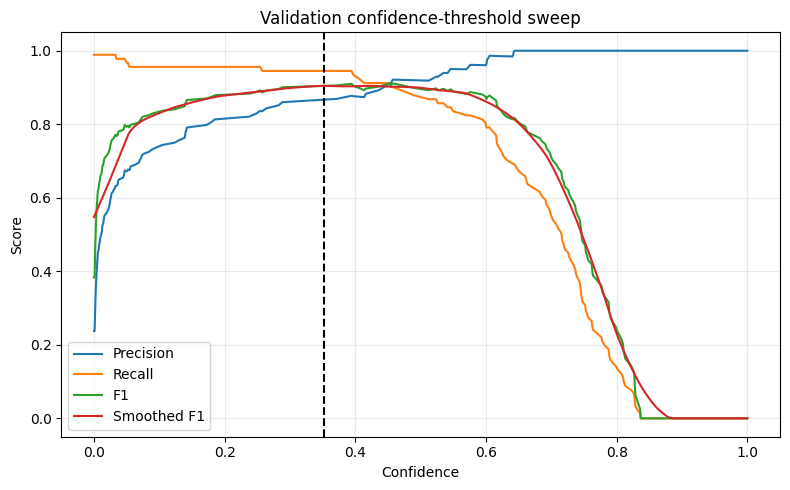

In [74]:
confidence_sweep = pd.DataFrame({
    "Confidence": validation_metrics.box.px,
    "Precision": validation_metrics.box.p_curve.mean(axis=0),
    "Recall": validation_metrics.box.r_curve.mean(axis=0),
    "F1": validation_metrics.box.f1_curve.mean(axis=0),
})
confidence_sweep["Smoothed F1"] = smooth(confidence_sweep["F1"].to_numpy(), 0.1)

best_index = confidence_sweep["Smoothed F1"].idxmax()
best_point = confidence_sweep.loc[best_index]
SELECTED_CONFIDENCE = float(best_point["Confidence"])

evaluation_folder = RESULTS_ROOT / "final_evaluation"
evaluation_folder.mkdir(parents=True, exist_ok=True)
confidence_sweep.to_csv(evaluation_folder / "validation_confidence_sweep.csv", index=False)

print(
    f"\nSelected confidence: {SELECTED_CONFIDENCE:.3f} | "
    f"Precision {best_point['Precision']:.3f} | Recall {best_point['Recall']:.3f} | "
    f"F1 {best_point['F1']:.3f}"
)
ax = confidence_sweep.plot(
    x="Confidence", y=["Precision", "Recall", "F1", "Smoothed F1"], figsize=(8, 5)
)
ax.axvline(SELECTED_CONFIDENCE, color="black", linestyle="--")
ax.set(title="Validation confidence-threshold sweep", ylabel="Score")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(evaluation_folder / "validation_confidence_sweep.png", dpi=300)
plt.show()


### Final test-set evaluation

Report AP across confidence thresholds and precision, recall and F1 at the selected confidence and IoU 0.50.

In [99]:
TEST_IOU = 0.50

# AP uses the full confidence ranking.
test_metrics = selected_model.val(
    data=str(OUTPUT_ROOT / "dataset.yaml"), split="test",
    imgsz=experiment_6_config["imgsz"], device=0, plots=True, verbose=False,
    project=str(evaluation_folder), name="test_ap", exist_ok=True,
)

# Precision, recall and F1 use the confidence selected on validation.
TEST_TP = TEST_FP = TEST_FN = 0
for image_path in sorted((OUTPUT_ROOT / "images" / "test").glob("*.jpg")):
    with Image.open(image_path) as image:
        width, height = image.size
    values = (OUTPUT_ROOT / "labels" / "test" / f"{image_path.stem}.txt").read_text().split()
    prediction = selected_model.predict(
        str(image_path), imgsz=experiment_6_config["imgsz"],
        conf=SELECTED_CONFIDENCE, device=0, verbose=False,
    )[0]
    predicted_boxes = prediction.boxes.xyxy

    matched = False
    if values:
        _, x, y, w, h = map(float, values)
        truth_box = torch.tensor([[
            (x - w / 2) * width, (y - h / 2) * height,
            (x + w / 2) * width, (y + h / 2) * height,
        ]], device=predicted_boxes.device)
        matched = bool(
            len(predicted_boxes)
            and box_iou(truth_box, predicted_boxes).max().item() >= TEST_IOU
        )

    TEST_TP += int(matched)
    TEST_FN += int(bool(values) and not matched)
    TEST_FP += len(predicted_boxes) - int(matched)

TEST_PRECISION = TEST_TP / (TEST_TP + TEST_FP)
TEST_RECALL = TEST_TP / (TEST_TP + TEST_FN)
TEST_F1 = 2 * TEST_PRECISION * TEST_RECALL / (TEST_PRECISION + TEST_RECALL)

final_test_results = pd.DataFrame([{
    "AP50": test_metrics.box.map50, "mAP50-95": test_metrics.box.map,
    "Precision": TEST_PRECISION, "Recall": TEST_RECALL, "F1": TEST_F1,
    "Confidence": SELECTED_CONFIDENCE
}])
final_test_results.to_csv(evaluation_folder / "final_test_results.csv", index=False)
display(final_test_results.style.format({
    metric: "{:.3f}" for metric in
    ["AP50", "mAP50-95", "Precision", "Recall", "F1", "Confidence"]
}))


Ultralytics 8.4.120  Python-3.13.14 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 245.844.2 MB/s, size: 18.3 KB)
val: Scanning C:\Users\ADAM-\Desktop\MSc Major Project\CWD\processed\labels\test.cache... 174 images, 82 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 174/174 66.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 20.6it/s 0.5s.2s
                   all        174         92      0.886      0.924      0.926      0.519
Speed: 0.3ms preprocess, 1.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to C:\Users\ADAM-\Desktop\MSc Major Project\CWD\results\final_evaluation\test_ap


,AP50,mAP50-95,Precision,Recall,F1,Confidence
0,0.926,0.519,0.878,0.935,0.905,0.351


### Final object-level confusion matrix

Summarise test-set true positives, false positives and false negatives at the locked thresholds.

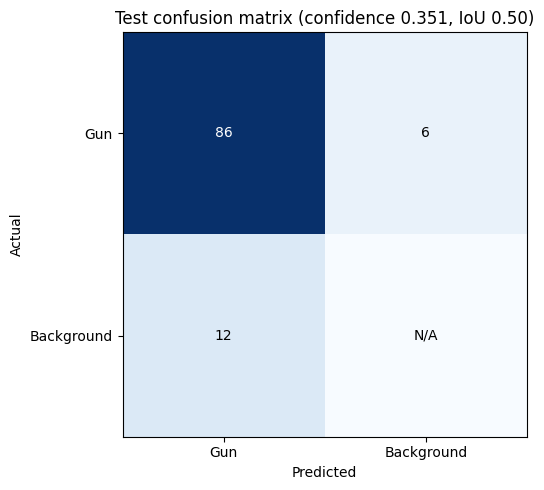

In [79]:
matrix = np.array([[TEST_TP, TEST_FN], [TEST_FP, np.nan]])
figure, axis = plt.subplots(figsize=(6, 5))
axis.imshow(np.nan_to_num(matrix), cmap="Blues")
axis.set(
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=["Gun", "Background"], yticklabels=["Gun", "Background"],
    xlabel="Predicted", ylabel="Actual",
    title=f"Test confusion matrix (confidence {SELECTED_CONFIDENCE:.3f}, IoU {TEST_IOU:.2f})",
)
for row, column in np.ndindex(matrix.shape):
    value = matrix[row, column]
    colour = "white" if value > np.nanmax(matrix) / 2 else "black"
    axis.text(
        column, row, "N/A" if np.isnan(value) else int(value),
        ha="center", va="center", color=colour,
    )
plt.tight_layout()
plt.savefig(evaluation_folder / "test_object_confusion_matrix.png", dpi=300)
plt.show()
